TypeError: Colorbar.__init__() got an unexpected keyword argument 'ax1'

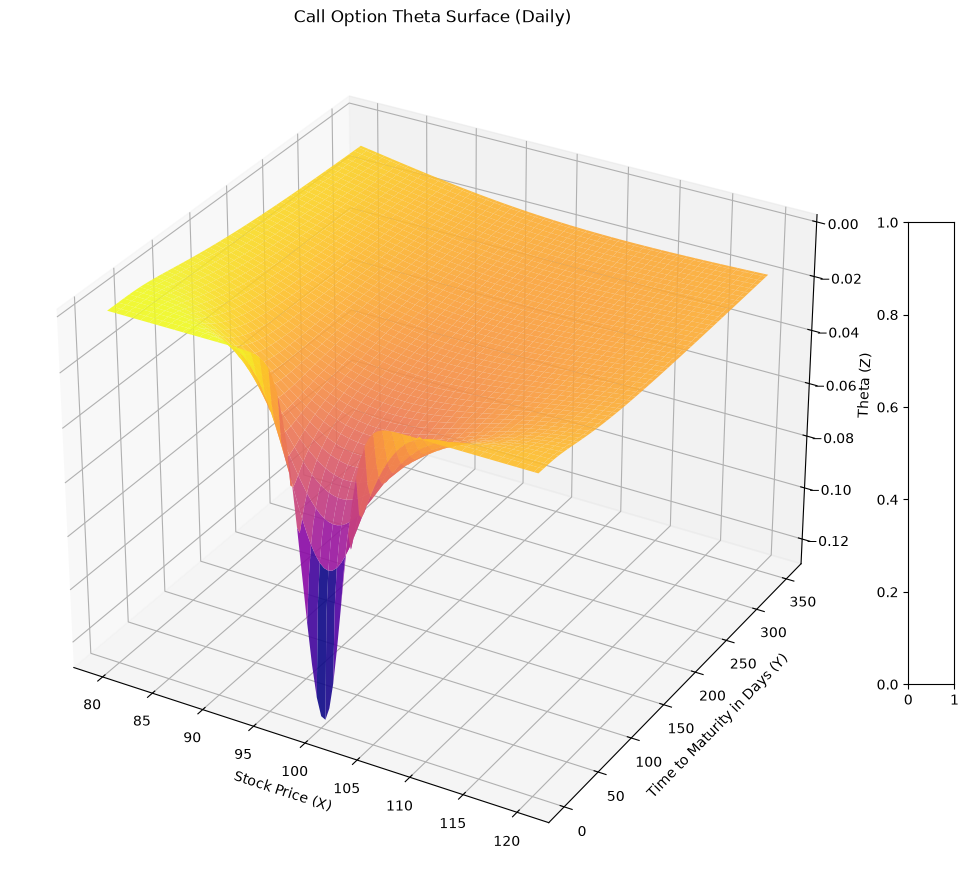

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# הגדרת פרמטרים קבועים
K = 100        # מחיר מימוש (Strike)
r = 0.05       # ריבית חסרת סיכון (5%)
sigma = 0.2    # תנודתיות משתמעת (20%)

# יצירת רשת נתונים (ציר מחיר מניה וציר ימים לפקיעה)
S = np.linspace(80, 120, 100)
T_days = np.linspace(3, 350, 100) # מניעת T=0 כדי להימנע מחלוקה באפס
T = T_days / 365.0

S_mesh, T_mesh = np.meshgrid(S, T)

# חישוב משתני עזר לפי מודל בלאק ושולס
d1 = (np.log(S_mesh / K) + (r + 0.5 * sigma**2) * T_mesh) / (sigma * np.sqrt(T_mesh))
d2 = d1 - sigma * np.sqrt(T_mesh)

# חישוב היווניות (Greeks)
vega = (S_mesh * np.sqrt(T_mesh) * norm.pdf(d1)) / 100.0  # ווגא לשינוי של 1% בתנודתיות
theta = (- (S_mesh * norm.pdf(d1) * sigma) / (2 * np.sqrt(T_mesh)) - r * K * np.exp(-r * T_mesh) * norm.cdf(d2)) / 365.0 # תטא ימית

# שרטוט הגרפים
fig = plt.figure(figsize=(30, 12))

# 1. גרף תטא
ax1 = fig.add_subplot(1, 2, 1, projection='3d')
surf1 = ax1.plot_surface(S_mesh, T_mesh * 365, theta, cmap='plasma', edgecolor='none', alpha=0.9)
ax1.set_title('Call Option Theta Surface (Daily)')
ax1.set_xlabel('Stock Price (X)')
ax1.set_ylabel('Time to Maturity in Days (Y)')
ax1.set_zlabel('Theta (Z)')
fig.colorbar(surf1, ax1=ax1, shrink=0.5, aspect=10, label='Theta')

# # 2. גרף ווגא
# ax2 = fig.add_subplot(1, 2, 2, projection='3d')
# surf2 = ax2.plot_surface(S_mesh, T_mesh * 365, vega, cmap='viridis', edgecolor='none', alpha=0.9)
# ax2.set_title('Call Option Vega Surface (per 1% Vol)')
# ax2.set_xlabel('Stock Price (X)')
# ax2.set_ylabel('Time to Maturity in Days (Y)')
# ax2.set_zlabel('Vega (Z)')
# fig.colorbar(surf2, ax2=ax2, shrink=0.5, aspect=10, label='Vega')

plt.tight_layout()
plt.show()

